In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Reproducibility
rng = np.random.default_rng(42)


In [3]:

df = pd.read_csv("data/final_cleaned_transactions.csv")

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

df["CustomerID"] = df["CustomerID"].astype(str)

# Retain rows needed for analysis
df = df.dropna(
    subset=["InvoiceNo", "InvoiceDate", "LineAmount"]
)

# Aggregate product lines into complete invoices
invoice_df = (
    df.groupby(["CustomerID", "InvoiceNo"], as_index=False)
      .agg(
          InvoiceDate=("InvoiceDate", "min"),
          InvoiceAmount=("LineAmount", "sum")
      )
)

# Model positive purchase invoices
invoice_df = invoice_df[
    invoice_df["InvoiceAmount"] > 0
].copy()

print(invoice_df.head())
print("Total invoices:", len(invoice_df))
print("Total customers:", invoice_df["CustomerID"].nunique())


  CustomerID  InvoiceNo         InvoiceDate  InvoiceAmount
0      12346     499763 2010-03-02 13:08:00          27.05
1      12346     513774 2010-06-28 13:53:00         142.31
2      12346     541431 2011-01-18 10:01:00       77183.60
3      12347     529924 2010-10-31 14:20:00         611.53
4      12347     537626 2010-12-07 14:57:00        1423.58
Total invoices: 36594
Total customers: 5852


In [4]:

# Historical observation period
start_date = invoice_df["InvoiceDate"].min()
end_date = invoice_df["InvoiceDate"].max()

observation_months = (
    (end_date - start_date).total_seconds()
    / (86400 * 30.4375)
)

if observation_months <= 0:
    raise ValueError("Observation period must be positive.")

# Customer-level historical frequency
customer_df = (
    invoice_df.groupby("CustomerID")
    .agg(
        purchase_count=("InvoiceNo", "nunique"),
        total_spending=("InvoiceAmount", "sum")
    )
    .reset_index()
)

# Estimated Poisson monthly rates
customer_df["lambda_monthly"] = (
    customer_df["purchase_count"] / observation_months
)

# Estimate Lognormal parameters
log_spending = np.log(invoice_df["InvoiceAmount"])

mu = log_spending.mean()
sigma = log_spending.std(ddof=0)

print("Observation months:", round(observation_months, 2))
print("Lognormal mu:", round(mu, 4))
print("Lognormal sigma:", round(sigma, 4))
print(customer_df.head())


Observation months: 24.25
Lognormal mu: 5.5987
Lognormal sigma: 1.0705
  CustomerID  purchase_count  total_spending  lambda_monthly
0      12346               3        77352.96        0.123694
1      12347               8         5633.32        0.329851
2      12348               5         1658.40        0.206157
3      12349               3         3678.69        0.123694
4      12350               1          294.40        0.041231


In [5]:

N_SIMULATIONS = 1000
FORECAST_MONTHS = 12

print("Number of simulations:", N_SIMULATIONS)
print("Forecast horizon:", FORECAST_MONTHS, "months")


Number of simulations: 1000
Forecast horizon: 12 months


In [6]:

rates = customer_df["lambda_monthly"].to_numpy()

# Store the simulated CLV for every customer
all_clv = np.zeros(
    (len(customer_df), N_SIMULATIONS)
)

BATCH_SIZE = 50

for start in range(0, len(customer_df), BATCH_SIZE):

    end = min(start + BATCH_SIZE, len(customer_df))
    batch_rates = rates[start:end]

    # Simulate future purchase counts
    counts = rng.poisson(
        lam=batch_rates[:, None] * FORECAST_MONTHS,
        size=(len(batch_rates), N_SIMULATIONS)
    )

    # Number of purchase events in this batch
    total_events = int(counts.sum())

    # Simulate each invoice amount
    simulated_amounts = rng.lognormal(
        mean=mu,
        sigma=sigma,
        size=total_events
    )

    # Assign spending to customer-simulation pairs
    event_ids = np.repeat(
        np.arange(counts.size),
        counts.ravel()
    )

    totals = np.bincount(
        event_ids,
        weights=simulated_amounts,
        minlength=counts.size
    )

    all_clv[start:end, :] = totals.reshape(counts.shape)

print("Monte Carlo simulation completed!")
print("Simulation matrix shape:", all_clv.shape)


Monte Carlo simulation completed!
Simulation matrix shape: (5852, 1000)


In [7]:

customer_df["predicted_clv"] = all_clv.mean(axis=1)

customer_df["clv_sd"] = all_clv.std(axis=1, ddof=1)

customer_df["clv_lower_95"] = np.percentile(
    all_clv, 2.5, axis=1
)

customer_df["clv_upper_95"] = np.percentile(
    all_clv, 97.5, axis=1
)

results = customer_df[
    [
        "CustomerID",
        "purchase_count",
        "lambda_monthly",
        "predicted_clv",
        "clv_sd",
        "clv_lower_95",
        "clv_upper_95"
    ]
]

print(results.head(10))

results.to_csv(
    "monte_carlo_customer_clv.csv",
    index=False
)


  CustomerID  purchase_count  lambda_monthly  predicted_clv       clv_sd  \
0      12346               3        0.123694     708.642848  1061.151319   
1      12347               8        0.329851    1869.207584  1621.300909   
2      12348               5        0.206157    1196.065744  1284.329142   
3      12349               3        0.123694     661.676341   837.155551   
4      12350               1        0.041231     253.527641   566.216447   
5      12351               1        0.041231     249.799742   630.765345   
6      12352               9        0.371083    2155.719016  1807.649761   
7      12353               2        0.082463     443.619407   667.137038   
8      12354               1        0.041231     220.251864   526.344366   
9      12355               2        0.082463     454.266889   752.728467   

   clv_lower_95  clv_upper_95  
0      0.000000   3482.078253  
1     53.755293   6197.182318  
2      0.000000   4887.053842  
3      0.000000   2895.313236  
4  

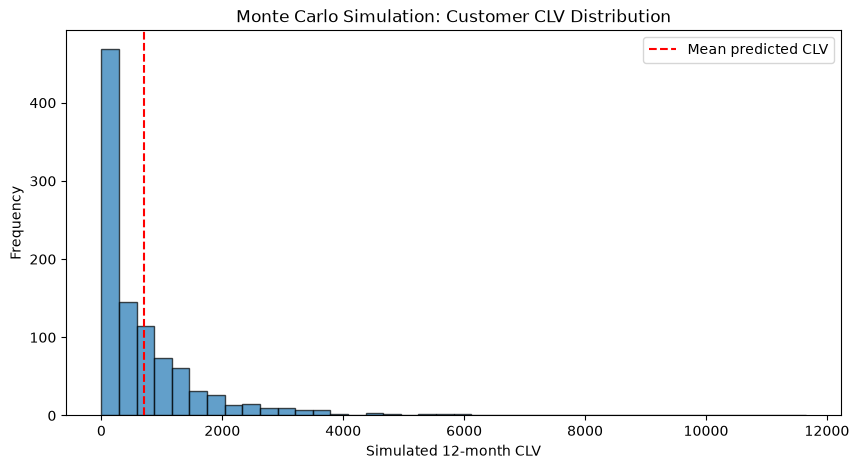

In [8]:

customer_index = 0

plt.figure(figsize=(10, 5))

plt.hist(
    all_clv[customer_index],
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    customer_df.loc[customer_index, "predicted_clv"],
    color="red",
    linestyle="--",
    label="Mean predicted CLV"
)

plt.xlabel("Simulated 12-month CLV")
plt.ylabel("Frequency")
plt.title("Monte Carlo Simulation: Customer CLV Distribution")
plt.legend()
plt.show()


Expected 12-month revenue: 8675562.14
95% simulation interval: [8460816.90507134 8903107.47443862]


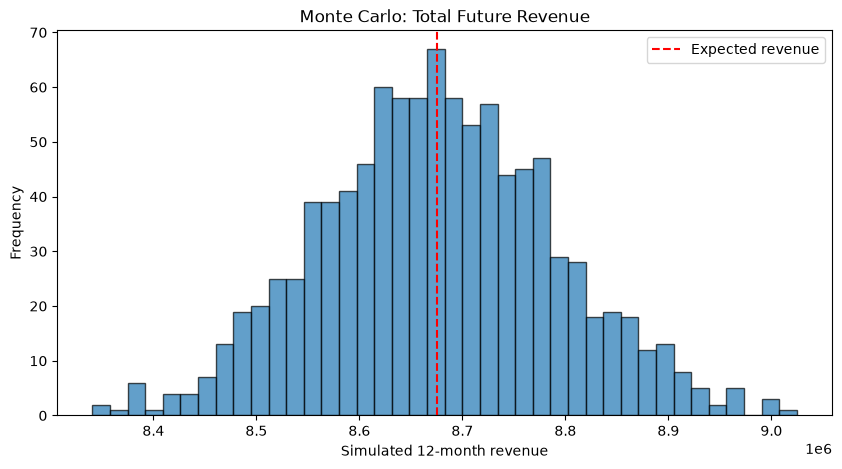

In [9]:

# Sum customer CLV across each simulation
portfolio_revenue = all_clv.sum(axis=0)

print(
    "Expected 12-month revenue:",
    round(portfolio_revenue.mean(), 2)
)

print(
    "95% simulation interval:",
    np.percentile(portfolio_revenue, [2.5, 97.5])
)

plt.figure(figsize=(10, 5))

plt.hist(
    portfolio_revenue,
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    portfolio_revenue.mean(),
    color="red",
    linestyle="--",
    label="Expected revenue"
)

plt.xlabel("Simulated 12-month revenue")
plt.ylabel("Frequency")
plt.title("Monte Carlo: Total Future Revenue")
plt.legend()
plt.show()


In [10]:

customer_df["theoretical_clv"] = (
    FORECAST_MONTHS
    * customer_df["lambda_monthly"]
    * np.exp(mu + sigma**2 / 2)
)

comparison = customer_df[
    ["CustomerID", "predicted_clv", "theoretical_clv"]
].copy()

comparison["relative_error"] = (
    np.abs(
        comparison["predicted_clv"]
        - comparison["theoretical_clv"]
    )
    / comparison["theoretical_clv"]
)

print(comparison.head())
print(
    "Mean relative error:",
    comparison["relative_error"].mean()
)


  CustomerID  predicted_clv  theoretical_clv  relative_error
0      12346     708.642848       710.922030        0.003206
1      12347    1869.207584      1895.792079        0.014023
2      12348    1196.065744      1184.870049        0.009449
3      12349     661.676341       710.922030        0.069270
4      12350     253.527641       236.974010        0.069854
Mean relative error: 0.03881681669248903
